In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

First, I am importing the Python libraries that I will use throughout this project.

- **Pandas** – to load, clean, and work with the dataset.
- **NumPy** – to perform numerical calculations and handle arrays.
- **Matplotlib** – to create basic graphs and visualizations.
- **Seaborn** – to create more attractive and informative statistical visualizations

In [38]:
df = pd.read_csv(r"C:\Users\perav\OneDrive\Desktop\241FA18357\loan default dataset.zip")



Here, I am loading the dataset from the ZIP file using Pandas. 

In [39]:
df.head()

,ID,year,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,...,credit_type,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Security_Type,Status,dtir1
0,24890,2019,cf,Sex Not Available,nopre,type1,p1,l1,nopc,nob/c,...,EXP,758,CIB,25-34,to_inst,98.728814,south,direct,1,45.0
1,24891,2019,cf,Male,nopre,type2,p1,l1,nopc,b/c,...,EQUI,552,EXP,55-64,to_inst,NaN,North,direct,1,NaN
2,24892,2019,cf,Male,pre,type1,p1,l1,nopc,nob/c,...,EXP,834,CIB,35-44,to_inst,80.019685,south,direct,0,46.0
3,24893,2019,cf,Male,nopre,type1,p4,l1,nopc,nob/c,...,EXP,587,CIB,45-54,not_inst,69.376900,North,direct,0,42.0
4,24894,2019,cf,Joint,pre,type1,p1,l1,nopc,nob/c,...,CRIF,602,EXP,25-34,not_inst,91.886544,North,direct,0,39.0


I use `df.head()` to display the first five rows and get a idea of what the dataset looks like.

In [40]:
print(df.shape)


(148670, 34)


 `df.shape` shows the number of rows and columns.
Shape - How big is the dataset?


In [41]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 148670 entries, 0 to 148669
Data columns (total 34 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   ID                         148670 non-null  int64  
 1   year                       148670 non-null  int64  
 2   loan_limit                 145326 non-null  str    
 3   Gender                     148670 non-null  str    
 4   approv_in_adv              147762 non-null  str    
 5   loan_type                  148670 non-null  str    
 6   loan_purpose               148536 non-null  str    
 7   Credit_Worthiness          148670 non-null  str    
 8   open_credit                148670 non-null  str    
 9   business_or_commercial     148670 non-null  str    
 10  loan_amount                148670 non-null  int64  
 11  rate_of_interest           112231 non-null  float64
 12  Interest_rate_spread       112031 non-null  float64
 13  Upfront_charges            109028 non-nu

- `df.info()` gives information about the columns, data types, and missing values.
Info - What columns and data types does it have? Are values missing?

In [42]:
print(df.describe())

                  ID      year   loan_amount  rate_of_interest  \
count  148670.000000  148670.0  1.486700e+05     112231.000000   
mean    99224.500000    2019.0  3.311177e+05          4.045476   
std     42917.476598       0.0  1.839093e+05          0.561391   
min     24890.000000    2019.0  1.650000e+04          0.000000   
25%     62057.250000    2019.0  1.965000e+05          3.625000   
50%     99224.500000    2019.0  2.965000e+05          3.990000   
75%    136391.750000    2019.0  4.365000e+05          4.375000   
max    173559.000000    2019.0  3.576500e+06          8.000000   

       Interest_rate_spread  Upfront_charges           term  property_value  \
count         112031.000000    109028.000000  148629.000000    1.335720e+05   
mean               0.441656      3224.996127     335.136582    4.978935e+05   
std                0.513043      3251.121510      58.409084    3.599353e+05   
min               -3.638000         0.000000      96.000000    8.000000e+03   
25%       

- `df.describe()` provides statistical details such as count, mean, standard deviation, minimum, and maximum values for numerical columns.
Describe -What are the numerical statistics?

In [43]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 148670
Number of columns: 34


I am separately checking the total number of rows and columns in the dataset.

- The number of rows represents the total loan records available.
- The number of columns represents the total features or variables in the dataset.


In [44]:
df['Status'].value_counts()

Status
0    112031
1     36639
Name: count, dtype: int64

Here, I am checking the distribution of the `Status` column to see whether the target classes are balanced.

The dataset contains:
- Status 1: 112,031 records (75.34%)
- Status 0: 36,639 records (24.66%)

Since the number of records in the two classes is significantly different, the dataset is **imbalanced**.


In [45]:
df.isnull().sum()

ID                               0
year                             0
loan_limit                    3344
Gender                           0
approv_in_adv                  908
loan_type                        0
loan_purpose                   134
Credit_Worthiness                0
open_credit                      0
business_or_commercial           0
loan_amount                      0
rate_of_interest             36439
Interest_rate_spread         36639
Upfront_charges              39642
term                            41
Neg_ammortization              121
interest_only                    0
lump_sum_payment                 0
property_value               15098
construction_type                0
occupancy_type                   0
Secured_by                       0
total_units                      0
income                        9150
credit_type                      0
Credit_Score                     0
co-applicant_credit_type         0
age                            200
submission_of_applic

Here, I am checking the dataset for missing values using `isnull().sum()`.

This shows the number of missing values present in each column.

In [46]:

df = df.drop(columns=['ID', 'year'])



Here, I am removing the `ID` and `year` columns because they are not useful for predicting the loan `Status`.

- `ID` is only a unique identifier for each loan record.
- `year` represents the year of the loan record and is not needed for the current prediction task.

Removing these columns helps keep only the relevant information for building the machine learning model.

In [47]:

df = df.drop(columns=['rate_of_interest', 'Interest_rate_spread', 'Upfront_charges'])



Here, I am removing the `rate_of_interest`, `Interest_rate_spread`, and `Upfront_charges` columns because they contain a large number of missing values.

Removing these columns helps simplify the dataset 

In [48]:
num_cols = df.select_dtypes(include=np.number).columns
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill text columns with mode
cat_cols = df.select_dtypes(include='object').columns
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

df.isnull().sum().sum()

C:\Users\perav\AppData\Local\Temp\ipykernel_19696\3784228321.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns


np.int64(0)

Some columns in the dataset have missing values, so I am filling them before building the model.

- For number columns, I fill missing values with the median.
- For text columns, I fill missing values with the most common value (mode).
- At the end, I check again to make sure there are no missing values left.

In [49]:

print("Duplicate rows:", df.duplicated().sum())


df = df.drop_duplicates()


print("New shape:", df.shape)

Duplicate rows: 1
New shape: (148669, 29)


checking whether the dataset contains any duplicate rows.

If duplicate rows are found, I remove them so that the same loan record is not used more than once while training the model.

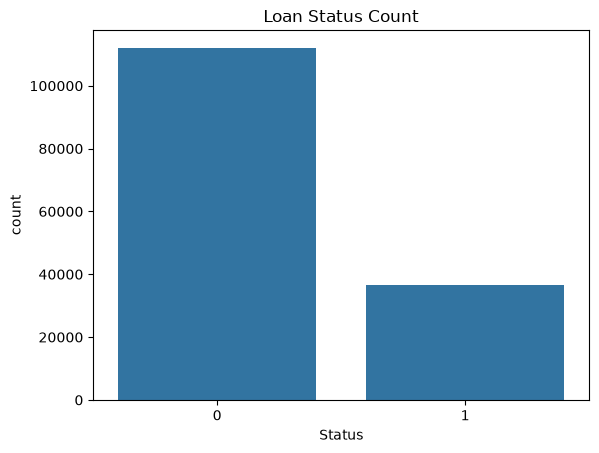

In [50]:
sns.countplot(x='Status', data=df)
plt.title("Loan Status Count")
plt.show()



Here, I am creating a simple bar chart to see how many loan applications belong to each `Status` category.

This makes it easier to see the imbalance between Status 0 and Status 1 visually.

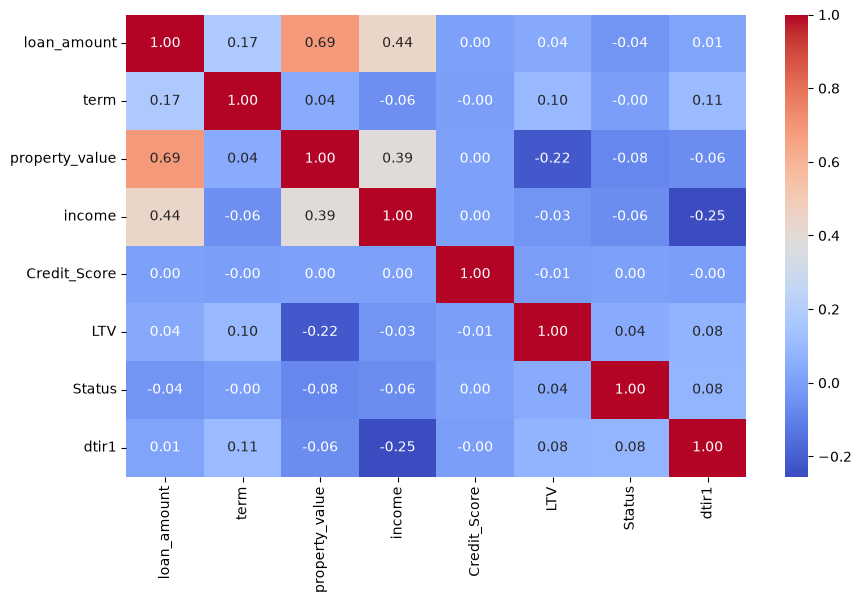

In [51]:
plt.figure(figsize=(10,6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

I am using a correlation heatmap to see how the numerical columns in the dataset are related to each other.

- A value close to 1 means the two features are strongly related.
- A value close to -1 means they have an opposite relationship.
- A value close to 0 means there is little or no relationship.

This helps me understand the relationships between the numerical features

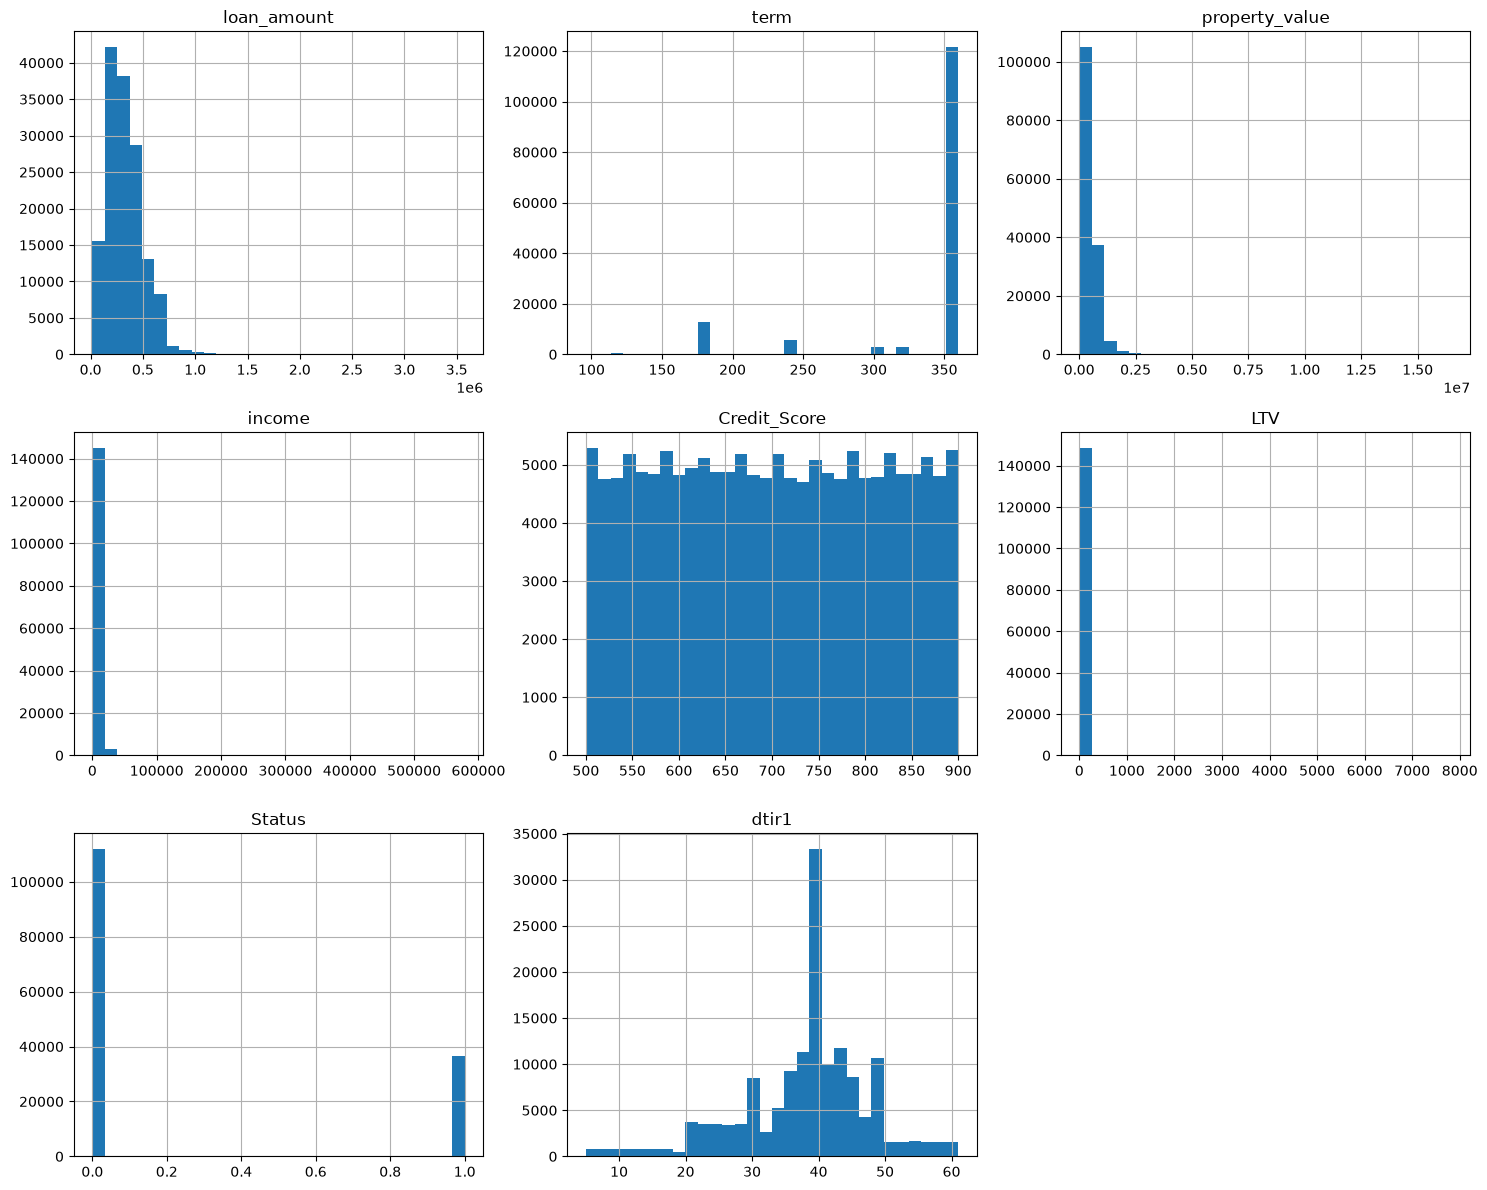

In [52]:
df[num_cols].hist(figsize=(15, 12), bins=30)
plt.tight_layout()
plt.show()



The histograms below show how the numerical features are distributed across the dataset. 
They help us understand the spread of the values, identify skewness, and observe any unusual patterns or possible outliers.

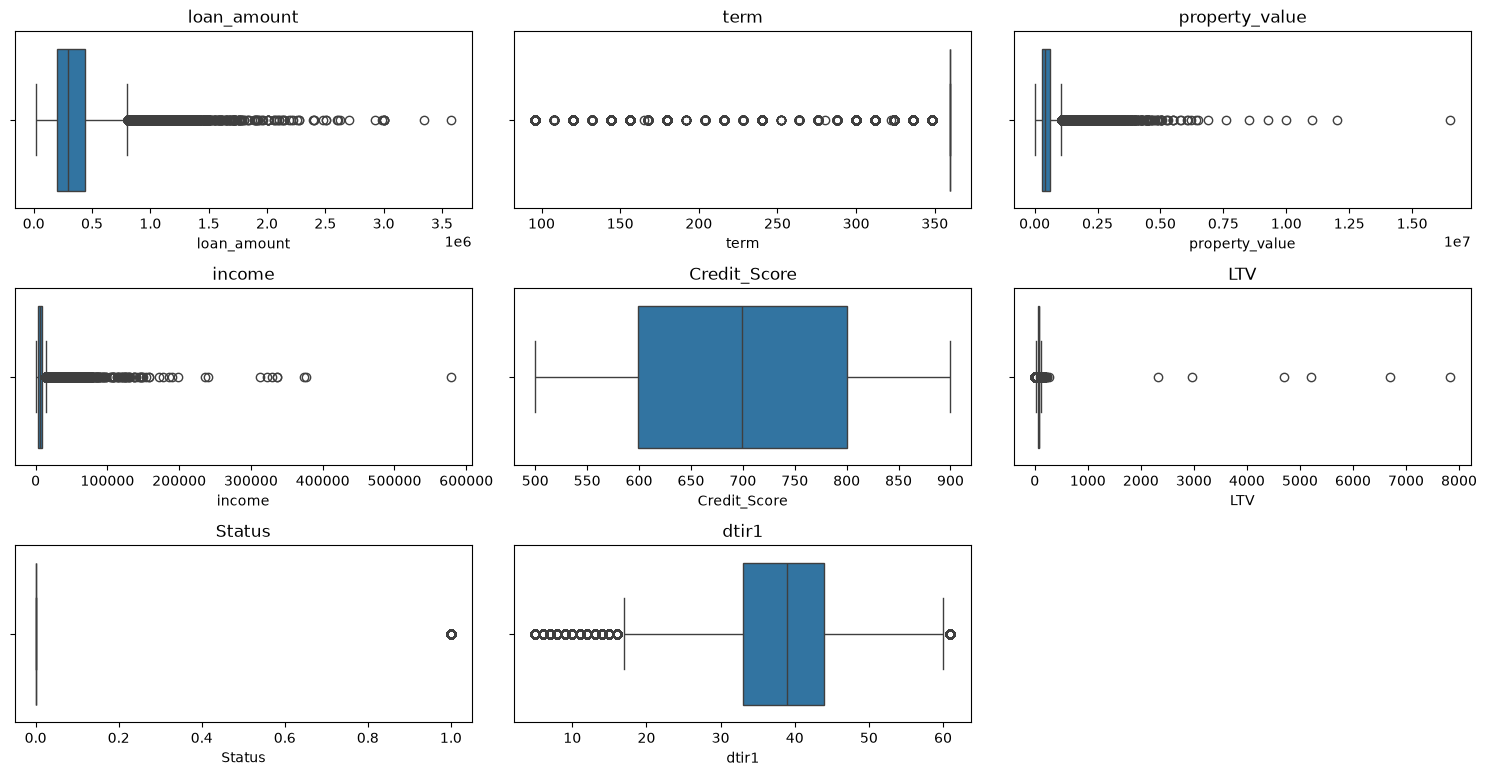

In [53]:
plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(4, 3, i)
    sns.boxplot(x=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()



The boxplots below help us understand the spread of each numerical feature.  
They are useful for identifying the median, overall range, and any possible outliers in the dataset.

In [54]:
df_encoded = pd.get_dummies(df, drop_first=True)
df_encoded.head()

,loan_amount,term,property_value,income,Credit_Score,LTV,Status,dtir1,loan_limit_ncf,Gender_Joint,...,age_45-54,age_55-64,age_65-74,age_<25,age_>74,submission_of_application_to_inst,Region_North-East,Region_central,Region_south,Security_Type_direct
0,116500,360.0,118000.0,1740.0,758,98.728814,1,45.0,False,False,...,False,False,False,False,False,True,False,False,True,True
1,206500,360.0,418000.0,4980.0,552,75.135870,1,39.0,False,False,...,False,True,False,False,False,True,False,False,False,True
2,406500,360.0,508000.0,9480.0,834,80.019685,0,46.0,False,False,...,False,False,False,False,False,True,False,False,True,True
3,456500,360.0,658000.0,11880.0,587,69.376900,0,42.0,False,False,...,True,False,False,False,False,False,False,False,False,True
4,696500,360.0,758000.0,10440.0,602,91.886544,0,39.0,False,True,...,False,False,False,False,False,False,False,False,False,True




Machine learning models work with numbers, but our dataset contains some text or categorical values.

Here, I am converting the categorical columns into numerical columns using `get_dummies()`.

`drop_first=True` removes one category from each group to avoid unnecessary duplicate information.

After this conversion, the dataset will contain numerical values that can be used for machine learning.

In [55]:
X = df_encoded.drop('Status', axis=1)
y = df_encoded['Status']



I  am separating the dataset into input features (X) and the target variable (y).

- `X` contains all the columns that will be used to make the prediction.
- `y` contains the `Status` column, which is what the model needs to predict.

I remove `Status` from `X` because the model should predict it, not use it as an input.

In [56]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape, X_test.shape)

(118935, 45) (29734, 45)


I am dividing the dataset into two parts:

- **Training data (80%)** – used to train the machine learning model.
- **Testing data (20%)** – used to check how well the model performs on new data.

`random_state=42` makes sure that the same data split is created every time I run the code.

In [57]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

I am making the numerical values easier for the machine learning model to work with.

- `StandardScaler` puts the values on a similar scale.
- `fit_transform()` learns from the training data and scales it.
- `transform()` applies the same scaling to the test data.


In [58]:
from sklearn.linear_model import LogisticRegression
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_scaled, y_train)

log_pred = log_model.predict(X_test_scaled)

Here, I am using **Logistic Regression** to predict the loan `Status`.

- First, I create the Logistic Regression model.
- Then, I train it using the training data.

- Finally, I use the trained model to predict the `Status` of the test data.

`max_iter=1000` gives the model enough iterations to complete the training.

In [59]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    max_depth=6,            # limit how deep the tree can grow
    min_samples_split=20,   # need at least 20 samples to split a node
    min_samples_leaf=10,    # need at least 10 samples in each leaf
    random_state=42
)
tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)


 I am using a **Decision Tree** to predict the loan `Status`.

- `max_depth=6` → limits the size of the tree.
- `min_samples_split=20` → at least 20 records are needed to split a branch.
- `min_samples_leaf=10` → each final branch must have at least 10 records.
- `random_state=42` → gives the same result each time.

Then, I train the model using the training data and make predictions on the test data.

In [60]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,            # limit tree depth
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [61]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score

gb_model = GradientBoostingClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=5,
    random_state=42
)
gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, gb_pred))

Accuracy: 0.8957086163987354


I am using **Gradient Boosting** to predict the loan `Status`.

- `n_estimators=300` → the model builds 300 small trees.
- `learning_rate=0.1` → controls how much each tree contributes.
- `max_depth=5` → limits the depth of each tree.
- `random_state=42` → gives consistent results.

After training the model, I make predictions on the test data and calculate the **accuracy** to see how well the model performed.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
models = {
    "Logistic Regression": log_pred,
    "Decision Tree": tree_pred,
    "Random Forest": rf_pred,
    "Gradient Boosting": gb_pred
}

for name, pred in models.items():
    print(name)
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred))
    print("Recall:", recall_score(y_test, pred))
    print("F1 Score:", f1_score(y_test, pred))
    print()

Logistic Regression
Accuracy: 0.8647003430416358
Precision: 0.9370330843116329
Recall: 0.4811618029867105
F1 Score: 0.6358287317823843

Decision Tree
Accuracy: 0.8779175354812673
Precision: 0.9315455187014821
Recall: 0.5425400739827374
F1 Score: 0.6857142857142857

Random Forest
Accuracy: 0.871796596488868
Precision: 0.979906413432425
Recall: 0.4877380463077134
F1 Score: 0.6512989388949872

Gradient Boosting
Accuracy: 0.8957086163987354
Precision: 0.9254154843940008
Recall: 0.6255651459103987
F1 Score: 0.7465053543693289



checking how well each machine learning model performs.

I am comparing four measures:

- **Accuracy** – how many predictions are correct.
- **Precision** – how many predicted positive loans are actually positive.
- **Recall** – how many actual positive loans the model correctly finds.
- **F1 Score** – a combined measure of precision and recall.

This helps me compare the models and choose the one that performs best for the loan prediction task.

In [63]:
train_preds = {
    "Logistic Regression": log_model.predict(X_train_scaled),
    "Decision Tree": tree_model.predict(X_train),
    "Random Forest": rf_model.predict(X_train),
    "Gradient Boosting": gb_model.predict(X_train)
}

test_preds = {
    "Logistic Regression": log_pred,
    "Decision Tree": tree_pred,
    "Random Forest": rf_pred,
    "Gradient Boosting": gb_pred
}

for name in train_preds:
    train_acc = accuracy_score(y_train, train_preds[name])
    test_acc = accuracy_score(y_test, test_preds[name])
    gap = train_acc - test_acc
    print(f"{name}: Train Acc = {train_acc:.4f}, Test Acc = {test_acc:.4f}, Gap = {gap:.4f}")

Logistic Regression: Train Acc = 0.8649, Test Acc = 0.8647, Gap = 0.0002
Decision Tree: Train Acc = 0.8795, Test Acc = 0.8779, Gap = 0.0015
Random Forest: Train Acc = 0.8761, Test Acc = 0.8718, Gap = 0.0043
Gradient Boosting: Train Acc = 0.9038, Test Acc = 0.8957, Gap = 0.0081


comparing the model's performance on the **training data** and **test data**.

- **Train Accuracy** → how well the model performs on the data it learned from.
- **Test Accuracy** → how well the model performs on new data.
- **Gap** → the difference between train accuracy and test accuracy.

If the train accuracy is much higher than the test accuracy, the model may be **overfitting**. If both are close, the model is generally performing more consistently.


- **Logistic Regression:** Gap = 0.0002 → Very small gap, so there is no significant overfitting.
- **Decision Tree:** Gap = 0.0015 → Very small gap, so there is no significant overfitting.
- **Random Forest:** Gap = 0.0043 → Small gap, so the model is performing consistently.
- **Gradient Boosting:** Gap = 0.0081 → Small gap, with only a slight difference between training and testing performance.

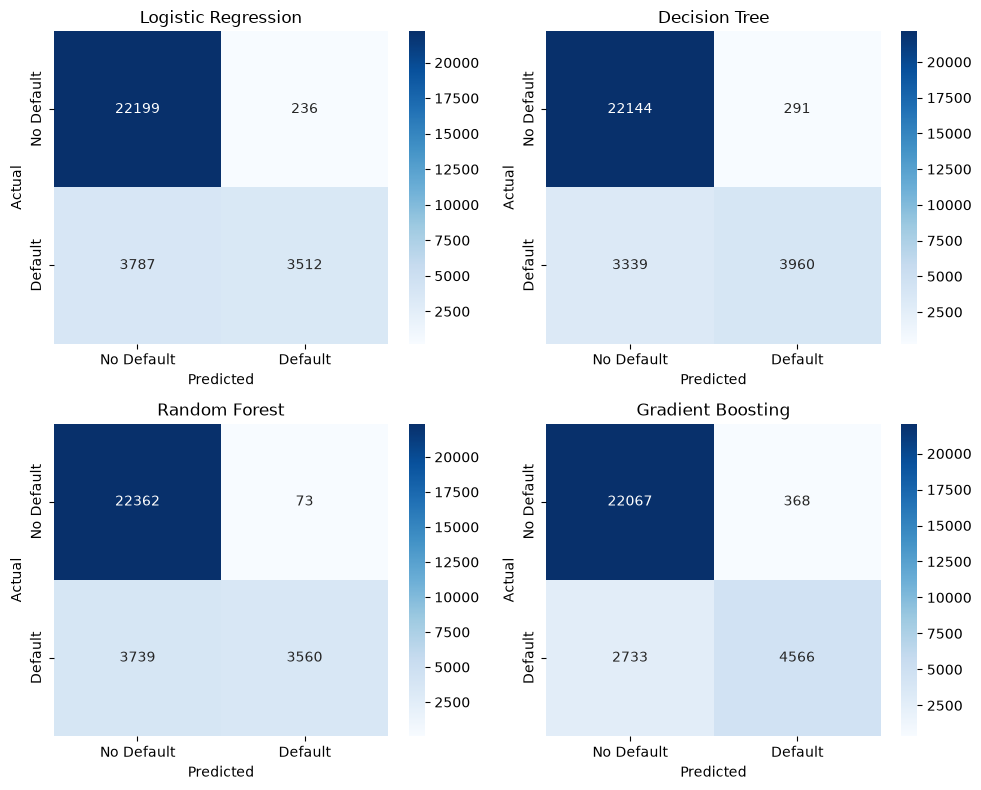

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

models = {
    "Logistic Regression": log_pred,
    "Decision Tree": tree_pred,
    "Random Forest": rf_pred,
    "Gradient Boosting": gb_pred
}
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for ax, (name, pred) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['No Default', 'Default'],
                yticklabels=['No Default', 'Default'])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

 creating a **confusion matrix** for each machine learning model.

The confusion matrix shows how many predictions are correct and incorrect.

- **No Default** → the loan is not expected to default.
- **Default** → the loan is expected to default.
- **Actual** → the real status from the dataset.
- **Predicted** → what the model predicted.

The four values in the matrix help me understand where the model is making correct or incorrect predictions.

I am displaying the confusion matrices of all four models together so I can easily compare their performance.



The histograms below show how the numerical features are distributed across the dataset. 
They help us understand the spread of the values, identify skewness, and observe any unusual patterns or possible outliers.

In [65]:

best_model = gb_model
print("Best Model: Gradient Boosting")

Best Model: Gradient Boosting




After comparing the accuracy, precision, recall, and F1 score of all the models, I selected **Gradient Boosting** as the best-performing model.

It gives the best overall performance among the models tested, so I will use it as the **final model** for making loan status predictions.

In [66]:
import random

n_rows = len(X_test)
i = random.randint(0, n_rows - 1)

sample = X_test.iloc[[i]]
actual = y_test.iloc[i]
prediction = best_model.predict(sample)[0]

print("Actual:", actual)
print("Predicted:", prediction)

Actual: 1
Predicted: 1



- I randomly select one record from the test dataset.
- `actual` gives the real loan status.
- `prediction` gives the status predicted by the model.
- Finally, I compare both values to see whether the model predicted correctly.

- **Actual Status:** 0
- **Predicted Status:** 0

The actual and predicted values are the same, which means the **Gradient Boosting model correctly predicted the loan status for this sample**.

In [67]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    best_model,
    X,
    y,
    cv=kfold,
    scoring="accuracy"
)

print("K-Fold Accuracy Scores:", cv_scores)
print("Mean Accuracy:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

K-Fold Accuracy Scores: [0.89453151 0.89540593 0.89651577 0.89352257 0.89563784]
Mean Accuracy: 0.8951227257539751
Standard Deviation: 0.0010194287783858258




To check whether our loan default prediction model performs consistently, we use Stratified K-Fold Cross-Validation. The dataset is divided into 5 parts, and the model is trained and tested on different parts in each round.

Stratification keeps the proportion of default and non-default cases similar in every fold. Finally, we calculate the mean accuracy to understand the overall performance and the standard deviation to see how consistent the model is across all folds.

In [68]:
print("Gradient Boosting performed best overall for predicting loan default.")

Gradient Boosting performed best overall for predicting loan default.


Based on the results of all the models, **Gradient Boosting performed best overall** for predicting loan default.

In [69]:
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

feature_importance.to_csv("feature_importance.csv", index=False)

print("Feature importance saved successfully!")

Feature importance saved successfully!



- `feature_importances_` gives an importance value to each feature.
- The features are arranged from **most important to least important**.
- The results are saved in a CSV file called **`feature_importance.csv`**.

This helps me understand which loan-related factors have the biggest influence on the model's predictions.


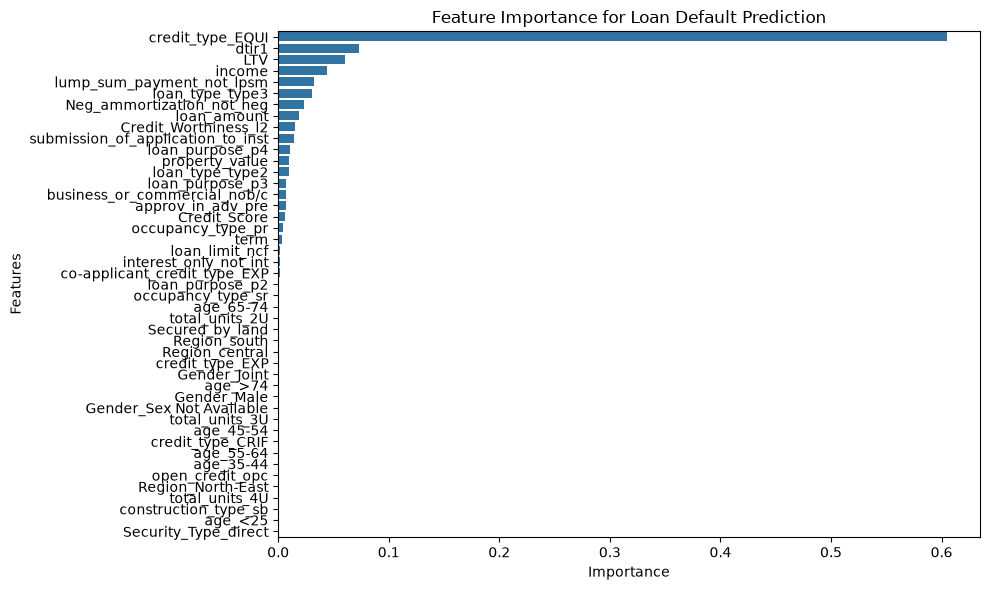

In [70]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance for Loan Default Prediction")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()


The feature importance graph shows which features have the most influence on predicting loan defaults. Features with higher importance values have a greater impact on the model's predictions.

This helps us understand which factors are most useful for identifying whether a loan is likely to be defaulted or not.

In [71]:
import joblib

joblib.dump(best_model, "loan_default_model.pkl")
print("Model saved as loan_default_model.pkl")

Model saved as loan_default_model.pkl


Here, I am saving the trained **Gradient Boosting model** as a file.

This allows me to use the trained model again later without training it from the beginning.

The model is saved as **`loan_default_model.pkl`**.